# 35 · CIFAR-10 transfer

The grayscale panel is primary. The RGB panel reuses the same originals and perturbation draws. Read both as matched tests of a fixed decision rule. [Protocol and reproduction instructions](../THEORY_STAGE10.md)

**Result.** In grayscale, retaining phase added 4.69 percentage points to category top-1 for linear weighting and 5.36 points for quadratic weighting. It added about 20 points to exact-source top-1 for each. The two phase fields were within 0.55 points of each other on either endpoint. Aligned ZNCC led exact-source retrieval at 98.54% in gray and 99.58% in RGB. RGB ResNet-50 final cosine led same-category retrieval at 20.68% within the tested methods.

In [1]:
from pathlib import Path
import sys
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json
from observables.stage10 import CLASSES, PRIMARY, load_cifar
R = ROOT/'results'/'stage10'/'cifar10'


## 1. Verify the gallery and encoder checkpoints

Twelve independent galleries of 40 originals have four images per category. Every original contributes eight transformed queries per panel. Exact-source top-1 searches all 40 candidates. Same-category top-1 searches 39 candidates after removing the source.

In [3]:
manifest = json.loads((R/'manifest.json').read_text())
membership = pd.read_csv(R/'membership.csv')
gray_ids = membership.query('panel == "gray"').drop(columns='panel').reset_index(drop=True)
rgb_ids = membership.query('panel == "rgb"').drop(columns='panel').reset_index(drop=True)
pd.testing.assert_frame_equal(gray_ids, rgb_ids)
assert gray_ids.source.nunique() == len(gray_ids) == 480
assert (gray_ids.groupby(['gallery', 'label']).size() == 4).all()
assert gray_ids.gallery.nunique() == 12

current = json.loads((R/'frozen_manifest.json').read_text())
fashion = json.loads((ROOT/'results'/'stage9'/'frozen_manifest.json').read_text())
for model in current['models']:
    assert current['models'][model]['sha256'] == fashion['models'][model]['sha256']
assert current['input_size'] == fashion['input_size'] == 56
display(pd.Series(manifest, name='Protocol').to_frame())


,Protocol
seed,10427
test_md5,40351d587109b95175f43aff81a1287e
test_sha256,f53d8d457504f7cff4ea9e021afcf0e0ad8e24a91f3fc4...
gallery_count,12
gallery_size,40
luma_coefficients,"[0.299, 0.587, 0.114]"
perturbations,"[shift, gain, noise, blur, rotation, crop, occ..."
floor,0.05
window,5
radius,3


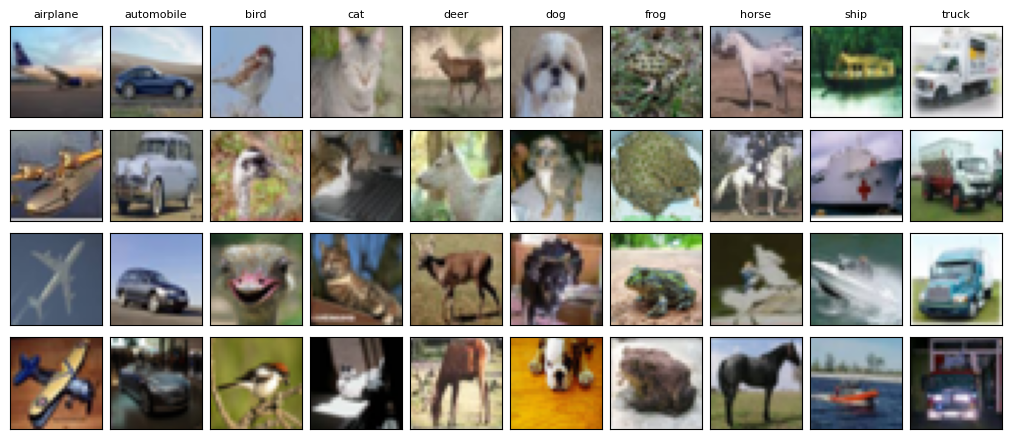

In [5]:
data = load_cifar()
assert data['test_sha256'] == manifest['test_sha256']
gallery = gray_ids.query('gallery == 0').sort_values(['label','source'])
fig, axes = plt.subplots(4, 10, figsize=(10, 4.3), layout='constrained')
for col, name in enumerate(CLASSES):
    axes[0, col].set_title(name, fontsize=8)
    for ax, source in zip(axes[:, col], gallery.query('label == @col').source):
        ax.imshow(data['x_test'][source])
        ax.set(xticks=[], yticks=[])
fig.savefig(R/'35_cifar10_gallery.png', dpi=150)
plt.show()


## 2. Top-1 and matched effects

Compare phase with magnitude within each exponent. The weighting contrast compares the two phase fields. Positive contrasts favor the first-named method. The uncertainty intervals are pointwise 95% gallery bootstraps.

In [7]:
summary = pd.read_csv(R/'summary.csv')
results = summary.pivot(index='method', columns='panel', values=['identity', 'class'])
table = 100 * results.reindex(columns=pd.MultiIndex.from_product([['gray', 'rgb'], ['identity', 'class']]).swaplevel())
table.columns = ['Gray source', 'Gray category', 'RGB source', 'RGB category']
display(table.round(2).sort_values('Gray category', ascending=False))

effects = pd.read_csv(R/'contrasts.csv')
effect_columns = ['difference', 'low95', 'high95']
display((effects.set_index(['panel','endpoint','contrast'])[effect_columns]*100).round(2))


,Gray source,Gray category,RGB source,RGB category
method,,,,
ResNet-50 local Q,75.10,16.95,88.39,16.82
ResNet-50 local mean,71.46,16.02,86.90,16.25
p2 phase,87.97,15.91,88.62,15.65
ResNet-50 cosine,47.71,15.83,65.23,20.68
p1 phase,87.68,15.36,88.36,15.21
EfficientNet-B0 local Q,69.84,14.92,81.51,17.37
EfficientNet-B0 cosine,47.14,14.56,59.22,17.92
aligned ZNCC,98.54,14.30,99.58,14.45
EfficientNet-B0 local mean,61.28,14.14,71.12,15.91


difference  low95  high95
panel          endpoint contrast                                         
gray           identity p1 phase gain                19.92  18.57   21.20
                        p2 phase gain                19.84  18.18   21.33
                        p1 minus p2 phase            -0.29  -1.20    0.62
                        phase-gain interaction        0.08  -1.04    1.20
rgb            identity p1 phase gain                20.44  19.37   21.54
                        p2 phase gain                20.26  18.52   21.74
                        p1 minus p2 phase            -0.26  -1.04    0.55
                        phase-gain interaction        0.18  -0.73    1.25
rgb minus gray identity p1 phase gain                 0.52   0.08    0.96
                        p2 phase gain                 0.42   0.03    0.86
                        p1 minus p2 phase             0.03  -0.57    0.60
                        phase-gain interaction        0.10  -0.62    0.76
gray           class    p1 phase gain                 4.69   2.24    7.14
                        p2 phase gain                 5.36   2.71    8.26
                        p1 minus p2 phase            -0.55  -1.25    0.16
                        phase-gain interaction       -0.68  -2.08    0.73
rgb            class    p1 phase gain                 4.48   2.27    6.56
                        p2 phase gain                 4.77   2.58    7.08
                        p1 minus p2 phase            -0.44  -1.35    0.44
                        phase-gain interaction       -0.29  -1.33    0.78
rgb minus gray class    p1 phase gain                -0.21  -1.04    0.60
                        p2 phase gain                -0.60  -1.98    0.76
                        p1 minus p2 phase             0.10  -0.68    0.83
                        phase-gain interaction        0.39  -0.83    1.64

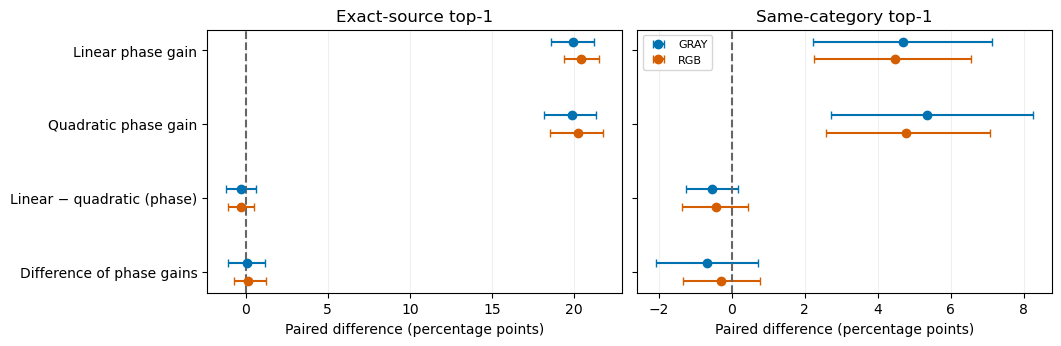

In [9]:
contrast_names = ['p1 phase gain', 'p2 phase gain', 'p1 minus p2 phase', 'phase-gain interaction']
labels = ['Linear phase gain', 'Quadratic phase gain', 'Linear − quadratic (phase)', 'Difference of phase gains']
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.35), sharey=True, layout='constrained')
positions = np.arange(len(labels))
for ax, endpoint, title in zip(axes, ['identity','class'], ['Exact-source top-1', 'Same-category top-1']):
    for panel, color, offset in [('gray', '#0072b2', -.12), ('rgb', '#d55e00', .12)]:
        view = 100 * effects.query('panel == @panel and endpoint == @endpoint').set_index('contrast').loc[contrast_names, effect_columns]
        ax.errorbar(view.difference, positions+offset,
                    xerr=[view.difference-view.low95, view.high95-view.difference],
                    fmt='o', color=color, capsize=3, label=panel.upper())
    ax.axvline(0, color='0.4', linestyle='--')
    ax.set(title=title, xlabel='Paired difference (percentage points)', yticks=positions, yticklabels=labels)
    ax.grid(axis='x', alpha=.2)
axes[0].invert_yaxis()
axes[1].legend(fontsize=8)
fig.savefig(R/'35_cifar10_contrasts.png', dpi=170)
plt.show()


## 3. Perturbation and cross-dataset checks

Condition summaries help distinguish robust category retrieval from recovery under a specific distortion. The cross-dataset table compares the shared linear phase contrast. Window size, search radius, and noise are fixed in pixel units. These datasets also differ in content, background, and effective signal strength.

In [11]:
by_condition = pd.read_csv(R/'condition_summary.csv')
class_curves = by_condition.query('panel == "gray" and method in @PRIMARY').pivot(
    index='condition', columns='method', values='class')
class_curves['linear gain'] = class_curves['p1 phase'] - class_curves['p1 magnitude']
class_curves['quadratic gain'] = class_curves['p2 phase'] - class_curves['p2 magnitude']
display((100 * class_curves).round(2))
past = pd.read_csv(ROOT/'results'/'stage9'/'transfer_contrasts.csv')
past = past.query('left == "aligned local Q" and right == "aligned Q magnitude" and panel in ["MNIST", "Fashion-MNIST"]')
now = effects.query('panel == "gray" and contrast == "p1 phase gain"').assign(panel='CIFAR-10 gray')
display((100 * pd.concat([past, now]).set_index(['panel', 'endpoint'])[effect_columns]).round(2))


method,p1 magnitude,p1 phase,p2 magnitude,p2 phase,linear gain,quadratic gain
condition,,,,,,
blur,9.79,12.50,10.83,12.71,2.71,1.88
crop,12.29,17.92,10.21,18.96,5.63,8.75
gain,13.12,17.92,13.75,19.38,4.79,5.62
noise,7.29,10.00,8.96,11.04,2.71,2.08
occlusion,10.00,18.54,11.25,18.33,8.54,7.08
rotation,10.83,15.83,10.42,14.79,5.00,4.38
shift,11.46,19.79,9.58,21.04,8.33,11.46
shift + noise,10.62,10.42,9.38,11.04,-0.21,1.67


difference  low95  high95
panel         endpoint                           
MNIST         identity        2.79   2.29    3.26
Fashion-MNIST identity       18.93  17.73   20.08
MNIST         class          10.86   8.12   13.78
Fashion-MNIST class          12.47  10.52   14.53
CIFAR-10 gray identity       19.92  18.57   21.20
              class           4.69   2.24    7.14

### Difference in the linear phase gain across datasets

Each dataset contributes paired phase-minus-magnitude effects within its own galleries. We independently resample the galleries from the two datasets when estimating the difference of gains. These contrasts compare benchmark panels and do not identify the cause of the change.

In [13]:
from observables.stage9 import cross_dataset_contrast
labels = {'aligned local Q': 'p1 phase', 'aligned Q magnitude': 'p1 magnitude'}
mnist = pd.read_csv(ROOT/'results'/'stage8'/'decisions.csv.gz').query(
    'panel == "replication" and gallery_type == "full" and method in @labels').replace({'method': labels})
fashion = pd.read_csv(ROOT/'results'/'stage9'/'decisions.csv.gz').query(
    'gallery_type == "full" and method in @labels').replace({'method': labels})
gray = pd.read_csv(R/'decisions.csv.gz').query('panel == "gray" and method in @PRIMARY')
deltas = [(name, endpoint, *cross_dataset_contrast(gray, prior, 'p1 phase', 'p1 magnitude', endpoint))
          for name, prior in [('MNIST', mnist), ('Fashion-MNIST', fashion)]
          for endpoint in ['identity', 'class']]
cross_panel = pd.DataFrame(deltas, columns=['CIFAR-10 gray minus', 'endpoint', *effect_columns])
cross_panel.to_csv(R/'cross_dataset_linear_phase_contrasts.csv', index=False)
display((100 * cross_panel.set_index(['CIFAR-10 gray minus', 'endpoint'])).round(2))


difference  low95  high95
CIFAR-10 gray minus endpoint                           
MNIST               identity       17.14  15.70   18.59
                    class          -6.17 -10.00   -2.45
Fashion-MNIST       identity        0.99  -0.78    2.79
                    class          -7.79 -11.09   -4.56

The grayscale linear phase benefit for exact-source retrieval is concentrated in noise, shift plus noise, and blur. Its category benefit is smaller than on either previous dataset. In RGB, the phase-versus-magnitude category gains are close to grayscale. The category estimates refer to these galleries and the 56 × 56 frozen encoder pipeline.